# 05 · Selección y reproducción desde Model Registry

Ejecutar en kernel nuevo. Dos familias finalistas para t+3, elegidas con CV. El hold-out se abre una sola vez para la evaluación final. Reejecuciones leen la selección guardada y verifican el mismo resultado desde Registry; no eligen otro ganador.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.datos import DATA, DOCS, EVIDENCE
from src.datos import execute
HAS_DATA = (DATA / "obt.parquet").exists()
display(Markdown("**OBT real local disponible**" if HAS_DATA else
    "**PENDIENTE:** faltan credenciales Snowflake válidas y snapshot. Este notebook no contiene resultados empíricos del ECU 911."))


**OBT real local disponible**

## Decisión y costos

AP de CV fija ganador y segundo; se contrasta diferencia con variación entre folds. Umbral elegido en OOF minimizando 5FN+FP sujeto a precision≥0.30, supuestos pendientes de validación operativa. Métrica de negocio: reducción de FN frente a baseline estacional. Se reportan alertas, precisión, recall, costos relativos, inferencia y estratos de volumen.

In [2]:
if HAS_DATA:
    selected = execute("seleccion")
    display(pd.DataFrame(selected))

2026/11/12 12:25:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'ecu911-alta-demanda-t3-modelo'.
2026/11/12 12:25:47 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ecu911-alta-demanda-t3-modelo, version 1
Created version '1' of model 'ecu911-alta-demanda-t3-modelo'.


🏃 View run final-t3-champion at: http://127.0.0.1:5001/#/experiments/1/runs/02f6f0e1c11a42f7a5c8202cfedf4fb8
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026/11/12 12:25:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'ecu911-alta-demanda-t3-modelo' already exists. Creating a new version of this model...
2026/11/12 12:25:58 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ecu911-alta-demanda-t3-modelo, version 2
Created version '2' of model 'ecu911-alta-demanda-t3-modelo'.


🏃 View run final-t3-challenger at: http://127.0.0.1:5001/#/experiments/1/runs/f5f6918ab4e44f8382c8d804cb1dd573
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,horizon,alias,name,run_id,selected_run_id,version,registry_name,threshold,cv_ap_mean,cv_ap_std,...,ap,precision,recall,tn,fp,fn,tp,cost_per_1000,alert_rate,inference_ms_per_row
0,3,champion,hist_boosting,02f6f0e1c11a42f7a5c8202cfedf4fb8,c147e507897848bd9ba538c03a85d427,1,ecu911-alta-demanda-t3-modelo,0.191241,0.213288,0.049684,...,0.320035,0.408868,0.278934,73607,3373,6031,2333,392.857143,0.066859,0.009151
1,3,challenger,random_forest,f5f6918ab4e44f8382c8d804cb1dd573,e1ac6adba5db4e9f93dfdb04587ebb9a,2,ecu911-alta-demanda-t3-modelo,0.250000,0.210112,0.056095,...,0.315776,0.405336,0.281564,73525,3455,6009,2355,392.529059,0.068077,0.016160


## Carga limpia por alias e igualdad exacta

`verify_registry` usa `mlflow.sklearn.load_model("models:/<proyecto>-t3-modelo@champion")`, sin depender del estimador que entrenó otro notebook. Comprueba predicciones idénticas y AP exactamente igual al run final en MLflow, para ambos aliases.

In [3]:
if HAS_DATA:
    display(execute("verificar"))
    from src.datos import context, export_runs
    runs = export_runs(context())
    print("Corridas exportadas:", len(runs))
    display(runs[["run_id", "status", "tags.fase", "tags.familia"]].head(12))

[{'horizon': 3, 'alias': 'champion', 'ap': 0.32003523524638633, 'exact': True},
 {'horizon': 3,
  'alias': 'challenger',
  'ap': 0.31577571732392523,
  'exact': True}]

Corridas exportadas: 106


,run_id,status,tags.fase,tags.familia
0,f5f6918ab4e44f8382c8d804cb1dd573,FINISHED,final,random_forest
1,02f6f0e1c11a42f7a5c8202cfedf4fb8,FINISHED,final,hist_boosting
2,f1eb624ced7d4178a6dee5bf74c823cc,FINISHED,tuning,logistica
3,1b040a816e1148f0a3b48174d44c6820,FINISHED,tuning,logistica
4,1721ce11a6fa432bba8be08c033486d9,FINISHED,tuning,logistica
5,599429a85d4e4901b6dd38809c66bcc9,FINISHED,tuning,logistica
6,17373ea3e5b141949ef971d14ec348ed,FINISHED,tuning,logistica
7,54ebf12c52ad490b9aaf31a5a25509bb,FINISHED,tuning,logistica
8,8d2fe280d2204344a9c79c1325f18abb,FINISHED,tuning,logistica
9,7b46187f33a54fbb9baa5194ff355cc9,FINISHED,tuning,logistica


## Evidencia para el documento técnico

Las tablas y gráficos de estos notebooks sirven para redactar el documento técnico por separado. El código no genera el PDF. La exportación de corridas a `docs/corridas.csv` se realiza en la celda anterior. La captura de MLflow puede obtenerse con `python -m src.datos captura`.

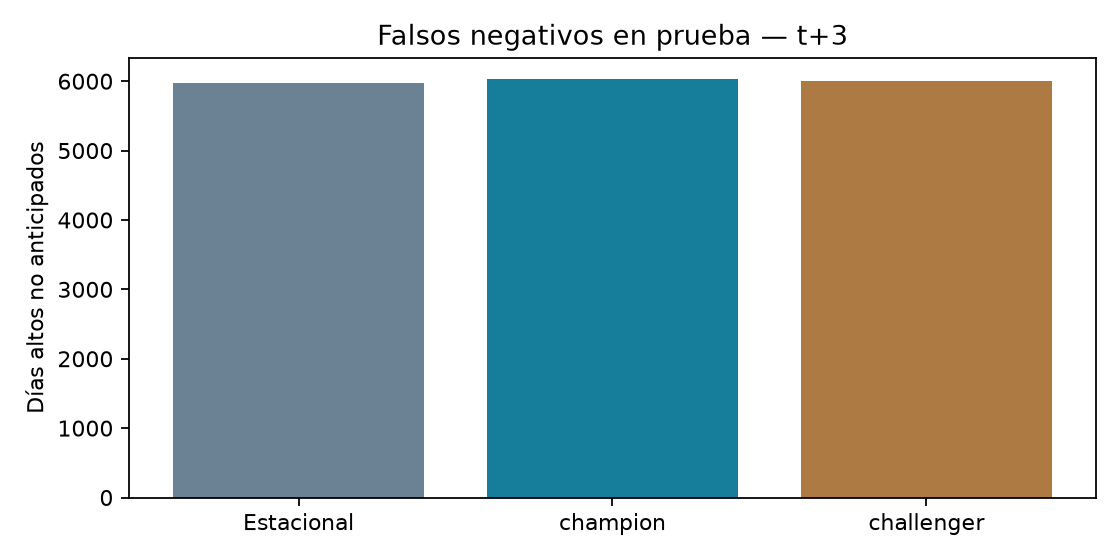

In [4]:
if HAS_DATA:
    from src.datos import plot_selection
    display(Image(filename=str(plot_selection(selected))))